# Medicaid Spending on Diabetes Medicines, 2020–2024

**Question:** How has Medicaid spending on diabetes medicines changed from 2020 to 2024, which drug classes are behind the change, and is the growth driven by more prescriptions or by higher spending per prescription? A secondary question: can simple models forecast this spending a year or two ahead?

**Data:** CMS *Medicaid Spending by Drug*, data year 2024 release (covers 2020–2024), downloaded from data.cms.gov. Figures are **gross spending before manufacturer rebates**, so they overstate Medicaid's net cost, by a large amount for brand-name drugs.

This notebook replaces an earlier version that used placeholder numbers. Every number below is computed from the CMS file.

In [1]:
import logging
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm notice from Prophet in plain Jupyter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from diabetes_spending import (
    DIABETES_CLASSES, OBESITY_CLASS, cagr, class_year_totals, decompose_growth,
    forecast_drift, forecast_linear, forecast_naive, load_diabetes_products, mape, sha256, to_long,
)

RAW = ROOT / "data" / "raw" / "DSD_MCD_RY26_P06_V20_D24_BGM.csv"
EXPECTED_SHA256 = "29294c174ee7ad6cbe97008b85af3f2887ff2600e6bb95503064fd5f27ae6624"
FIGS = ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

pd.set_option("display.float_format", "{:,.2f}".format)
logging.getLogger("cmdstanpy").disabled = True
logging.getLogger("prophet").setLevel(logging.ERROR)
logging.getLogger("prophet.plot").disabled = True  # optional plotly backend not needed

# Chart style: palette slots in fixed order, thin lines, recessive grid
BLUE, ORANGE, AQUA, YELLOW, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
})

## 1. Data provenance

In [2]:
assert sha256(RAW) == EXPECTED_SHA256, "Raw file differs from the documented CMS release"
raw = pd.read_csv(RAW)
print(f"CMS file: {raw.shape[0]:,} rows x {raw.shape[1]} columns; "
      f"{(raw['Mftr_Name'] == 'Overall').sum():,} national 'Overall' brand rows")

CMS file: 18,511 rows x 36 columns; 4,774 national 'Overall' brand rows


## 2. Identifying diabetes medicines

Products are classified from the generic name (`Gnrc_Name`) using the rules in `src/diabetes_spending.py` (unit-tested in `tests/`). Only each brand's national `Overall` row is used, so manufacturer-level rows aren't double counted.

* **Obesity-labeled incretins** (Wegovy, Saxenda, Zepbound) contain the same molecules as diabetes products but are labeled for weight management. They're tracked separately and **excluded from diabetes totals**.
* SGLT2 inhibitors are also prescribed for heart failure and kidney disease, and the file doesn't record the indication, so their spending isn't exclusively for diabetes.
* Fixed-dose combinations (e.g. Janumet, Synjardy, Soliqua) form their own class.

In [3]:
products = load_diabetes_products(RAW)
summary = (products.groupby("drug_class")
           .agg(products=("Brnd_Name", "size"),
                example_brands=("Brnd_Name", lambda s: ", ".join(sorted(s)[:4])))
           .reindex(DIABETES_CLASSES + [OBESITY_CLASS]))
summary

,products,example_brands
drug_class,,
GLP-1 / GIP-GLP-1 RA,9,"Bydureon Bcise, Byetta, Liraglutide, Mounjaro"
SGLT2 inhibitor,6,"Dapagliflozin, Farxiga, Inpefa, Invokana"
Insulin,72,"Admelog, Admelog Solostar, Afrezza, Apidra"
DPP-4 inhibitor,7,"Alogliptin, Januvia, Nesina, Onglyza"
Fixed-dose combination,29,"Actoplus Met, Alogliptin-Metformin, Alogliptin..."
Metformin,6,"Glumetza, Metformin ER Gastric, Metformin ER O..."
Sulfonylurea,7,"Glimepiride, Glipizide, Glipizide ER, Glipizid..."
Thiazolidinedione,2,"Actos, Pioglitazone HCl"
"Other (meglitinide, AGI, amylin)",6,"Acarbose, Miglitol, Nateglinide, Repaglinide"


## 3. Spending by drug class

In [4]:
long = to_long(products)
totals = class_year_totals(long)
spend_bn = totals.pivot(index="drug_class", columns="year", values="spending").reindex(DIABETES_CLASSES + [OBESITY_CLASS]) / 1e9
spend_bn["CAGR 2020-24 %"] = [cagr(r[2020], r[2024], 4) * 100 for _, r in spend_bn.iterrows()]
spend_bn.round(3)

year,2020,2021,2022,2023,2024,CAGR 2020-24 %
drug_class,,,,,,
GLP-1 / GIP-GLP-1 RA,1.50,2.49,4.05,6.41,7.21,48.09
SGLT2 inhibitor,0.81,1.31,2.01,2.86,3.34,42.64
Insulin,4.24,4.39,4.22,4.03,1.73,-20.02
DPP-4 inhibitor,0.81,0.92,0.93,0.92,0.82,0.17
Fixed-dose combination,0.27,0.29,0.32,0.40,0.40,10.66
Metformin,0.11,0.11,0.12,0.15,0.16,8.36
Sulfonylurea,0.03,0.03,0.03,0.03,0.03,2.37
Thiazolidinedione,0.01,0.01,0.01,0.01,0.01,-0.03
"Other (meglitinide, AGI, amylin)",0.01,0.01,0.01,0.01,0.00,-2.71


In [5]:
diab = totals[totals.drug_class != OBESITY_CLASS].groupby("year")[["spending", "claims"]].sum()
diab["spend_per_claim"] = diab["spending"] / diab["claims"]
overview = pd.DataFrame({
    "Diabetes spending ($bn)": diab["spending"] / 1e9,
    "Claims (millions)": diab["claims"] / 1e6,
    "Spending per claim ($)": diab["spend_per_claim"],
    "GLP-1 share of diabetes spending (%)": spend_bn.loc["GLP-1 / GIP-GLP-1 RA", diab.index] * 1e9 / diab["spending"] * 100,
    "Obesity-labeled incretins ($bn, excluded)": spend_bn.loc[OBESITY_CLASS, diab.index],
})
print(f"Diabetes spending CAGR 2020-2024: {cagr(diab.spending.iloc[0], diab.spending.iloc[-1], 4):.1%}")
overview

Diabetes spending CAGR 2020-2024: 15.2%


,Diabetes spending ($bn),Claims (millions),Spending per claim ($),GLP-1 share of diabetes spending (%),"Obesity-labeled incretins ($bn, excluded)"
year,,,,,
2020,7.78,30.72,253.22,19.26,0.01
2021,9.57,32.61,293.47,26.05,0.03
2022,11.70,34.03,343.80,34.62,0.12
2023,14.82,36.51,405.77,43.27,0.66
2024,13.70,34.73,394.36,52.61,1.56


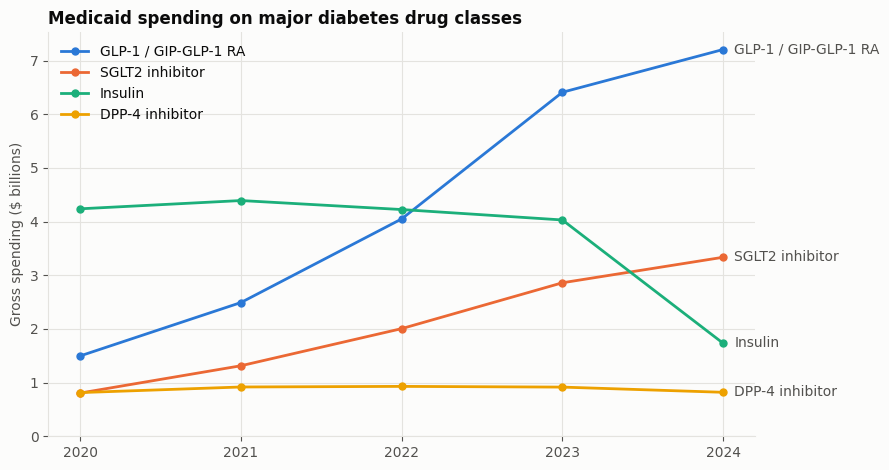

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.8))
major = {"GLP-1 / GIP-GLP-1 RA": BLUE, "SGLT2 inhibitor": ORANGE, "Insulin": AQUA, "DPP-4 inhibitor": YELLOW}
years = list(diab.index)
for cls, color in major.items():
    y = spend_bn.loc[cls, years]
    ax.plot(years, y, color=color, marker="o", markersize=5)
    ax.annotate(cls, (years[-1], y.iloc[-1]), xytext=(8, 0), textcoords="offset points", va="center", color=INK2)
ax.set_xticks(years)
ax.set_ylabel("Gross spending ($ billions)")
ax.set_ylim(bottom=0)
ax.set_title("Medicaid spending on major diabetes drug classes")
ax.legend(list(major), loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(FIGS / "spending_by_class.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Volume or price? Decomposing 2020→2024 growth

Spending = claims × spending per claim, so log growth splits exactly into a **claim-volume** part and a **spending-per-claim** part. Values are log points × 100 (roughly percent change for small values); the two parts add up to the total.

In [7]:
rows = []
for cls in DIABETES_CLASSES:
    s = totals[totals.drug_class == cls].set_index("year")
    d = decompose_growth(s.spending[2020], s.spending[2024], s.claims[2020], s.claims[2024])
    rows.append({"drug_class": cls, "total": d["log_growth"] * 100,
                 "claim volume": d["volume_log"] * 100, "spending per claim": d["spend_per_claim_log"] * 100})
d = decompose_growth(diab.spending[2020], diab.spending[2024], diab.claims[2020], diab.claims[2024])
rows.append({"drug_class": "All diabetes", "total": d["log_growth"] * 100,
             "claim volume": d["volume_log"] * 100, "spending per claim": d["spend_per_claim_log"] * 100})
decomp = pd.DataFrame(rows).set_index("drug_class")
decomp.round(1)

,total,claim volume,spending per claim
drug_class,,,
GLP-1 / GIP-GLP-1 RA,157.10,138.60,18.40
SGLT2 inhibitor,142.10,105.20,36.90
Insulin,-89.40,-16.00,-73.40
DPP-4 inhibitor,0.70,-37.40,38.10
Fixed-dose combination,40.50,-3.90,44.50
Metformin,32.10,-10.50,42.70
Sulfonylurea,9.40,-29.70,39.10
Thiazolidinedione,-0.10,-11.80,11.70
"Other (meglitinide, AGI, amylin)",-11.00,-20.00,9.10


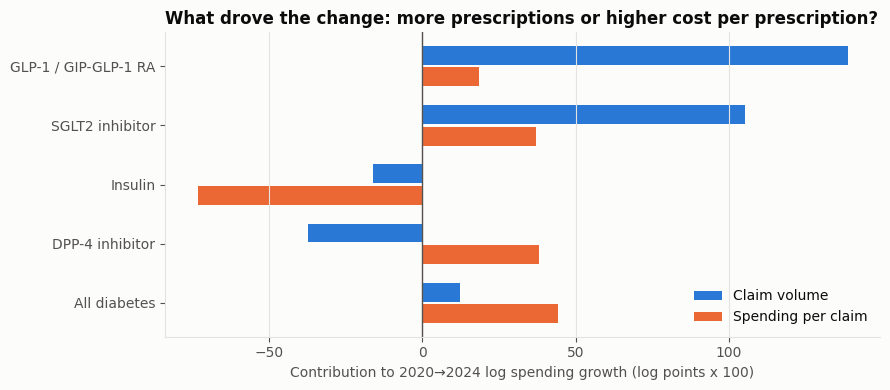

In [8]:
show = decomp.loc[["GLP-1 / GIP-GLP-1 RA", "SGLT2 inhibitor", "Insulin", "DPP-4 inhibitor", "All diabetes"]][::-1]
fig, ax = plt.subplots(figsize=(9, 4))
yy = np.arange(len(show))
h = 0.36
ax.barh(yy + h / 2, show["claim volume"], height=h - 0.04, color=BLUE, label="Claim volume")
ax.barh(yy - h / 2, show["spending per claim"], height=h - 0.04, color=ORANGE, label="Spending per claim")
ax.axvline(0, color=INK2, linewidth=1)
ax.set_yticks(yy, show.index)
ax.set_xlabel("Contribution to 2020→2024 log spending growth (log points x 100)")
ax.set_title("What drove the change: more prescriptions or higher cost per prescription?")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGS / "growth_decomposition.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Largest products in 2024

In [9]:
top = (long[long.drug_class != OBESITY_CLASS]
       .pivot_table(index=["Brnd_Name", "drug_class"], columns="year", values="spending", aggfunc="sum")
       .sort_values(2024, ascending=False).head(10) / 1e6)
top.columns = [f"{c} ($M)" for c in top.columns]
top.round(1)

,,2020 ($M),2021 ($M),2022 ($M),2023 ($M),2024 ($M)
Brnd_Name,drug_class,,,,,
Ozempic,GLP-1 / GIP-GLP-1 RA,274.50,492.90,976.30,"2,146.00","3,412.20"
Jardiance,SGLT2 inhibitor,461.50,776.10,"1,242.30","1,832.20","2,241.30"
Trulicity,GLP-1 / GIP-GLP-1 RA,594.50,"1,183.30","2,149.20","2,870.80","2,169.30"
Mounjaro,GLP-1 / GIP-GLP-1 RA,0.00,0.00,34.00,451.70,993.00
Farxiga,SGLT2 inhibitor,109.10,239.10,452.50,757.30,816.90
Januvia,DPP-4 inhibitor,573.40,658.80,691.30,694.70,646.70
Rybelsus,GLP-1 / GIP-GLP-1 RA,9.40,59.50,161.80,279.20,311.40
Lantus Solostar,Insulin,748.50,929.30,971.10,915.90,247.20
Basaglar Kwikpen U-100,Insulin,633.10,479.00,398.00,270.70,186.60


## 6. Insulin in 2024

Insulin gross spending fell sharply in 2024. The table compares claims with spending for the largest insulin products. This timing coincides with the removal of the Medicaid drug rebate cap (January 2024) and manufacturers' announced list-price cuts for several insulins. Because this file reports gross, pre-rebate spending, the fall mainly reflects pricing changes, not less insulin use. Claims are a better indicator of use.

In [10]:
ins = (long[long.drug_class == "Insulin"]
       .pivot_table(index="Brnd_Name", columns="year", values=["spending", "claims"], aggfunc="sum"))
ins = ins[ins[("spending", 2023)].notna()].sort_values(("spending", 2023), ascending=False).head(8)
ins_tbl = pd.DataFrame({
    "Spending 2023 ($M)": ins[("spending", 2023)] / 1e6,
    "Spending 2024 ($M)": ins[("spending", 2024)] / 1e6,
    "Spending change (%)": (ins[("spending", 2024)] / ins[("spending", 2023)] - 1) * 100,
    "Claims change (%)": (ins[("claims", 2024)] / ins[("claims", 2023)] - 1) * 100,
})
cls_ins = totals[totals.drug_class == "Insulin"].set_index("year")
print(f"All insulin: spending {cls_ins.spending[2024] / cls_ins.spending[2023] - 1:+.1%}, "
      f"claims {cls_ins.claims[2024] / cls_ins.claims[2023] - 1:+.1%} (2023 to 2024)")
ins_tbl.round(1)

All insulin: spending -57.0%, claims -10.5% (2023 to 2024)


,Spending 2023 ($M),Spending 2024 ($M),Spending change (%),Claims change (%)
Brnd_Name,,,,
Lantus Solostar,915.90,247.20,-73.00,14.50
Humalog,286.20,73.30,-74.40,-18.70
Novolog Flexpen,284.60,58.80,-79.30,-29.00
Humalog Kwikpen U-100,271.00,84.70,-68.80,-5.60
Basaglar Kwikpen U-100,270.70,186.60,-31.00,-31.10
Lantus,201.70,43.80,-78.30,-12.20
Levemir Flexpen,173.70,44.70,-74.30,-30.40
Novolog,153.10,36.10,-76.40,-19.50


## 7. Can we forecast it? A holdout backtest

There are only five annual observations, so any forecast is fragile. To check whether forecasting adds value, each model is fit on **2020–2022** and scored on the held-out **2023–2024** values (horizons of 1 and 2 years):

* **Naive:** carry the last value forward.
* **Drift:** extend the average annual change.
* **Linear trend:** ordinary least squares on year.
* **Prophet:** linear growth, no seasonality (annual data), no changepoints (three points can't support any).

Metric: mean absolute percentage error (MAPE) over the two held-out years, plus mean absolute error in $ millions.

In [11]:
from prophet import Prophet

def forecast_prophet(y, first_year, horizon, return_interval=False):
    ds = pd.to_datetime([f"{first_year + i}-01-01" for i in range(len(y))])
    m = Prophet(growth="linear", yearly_seasonality=False, weekly_seasonality=False,
                daily_seasonality=False, n_changepoints=0, interval_width=0.8)
    m.fit(pd.DataFrame({"ds": ds, "y": y}))
    future = pd.DataFrame({"ds": pd.to_datetime([f"{first_year + len(y) + i}-01-01" for i in range(horizon)])})
    fc = m.predict(future)
    return (fc["yhat"].values, fc[["yhat_lower", "yhat_upper"]].values) if return_interval else fc["yhat"].values

np.random.seed(42)
series = {cls: totals[totals.drug_class == cls].set_index("year")["spending"] for cls in list(major)}
series["All diabetes"] = diab["spending"]
models = {"Naive": forecast_naive, "Drift": forecast_drift, "Linear trend": forecast_linear,
          "Prophet": lambda y, h: forecast_prophet(y, 2020, h)}

records = []
for name, s in series.items():
    y = s.values.astype(float)
    train, test = y[:3], y[3:]
    for model, f in models.items():
        pred = f(train, len(test))
        records.append({"series": name, "model": model, "MAPE %": mape(test, pred),
                        "MAE $M": np.mean(np.abs(test - pred)) / 1e6})
backtest = pd.DataFrame(records)
backtest.pivot(index="series", columns="model", values="MAPE %").round(1)

model,Drift,Linear trend,Naive,Prophet
series,,,,
All diabetes,10.90,10.90,17.80,10.90
DPP-4 inhibitor,17.60,19.40,7.40,19.40
GLP-1 / GIP-GLP-1 RA,12.60,14.00,40.30,14.10
Insulin,73.70,76.00,74.20,76.00
SGLT2 inhibitor,6.40,7.40,34.90,7.40


In [12]:
backtest.groupby("model")[["MAPE %", "MAE $M"]].mean().sort_values("MAPE %").round(1)

,MAPE %,MAE $M
model,,
Drift,24.30,811.10
Linear trend,25.50,849.80
Prophet,25.60,850.60
Naive,34.90,"1,562.30"


## 8. Illustrative projection, 2025–2026

Fit on all five years. These are **projections under the assumption that the 2020–2024 trend continues**, not validated forecasts. The backtest above shows errors of more than 10% even for the total, and the 2024 insulin repricing shows how a single policy change can break a trend. The Prophet band is an 80% interval that only reflects scatter around the line, not structural changes, so it understates the real uncertainty.

In [13]:
rows = []
for name in ["All diabetes", "GLP-1 / GIP-GLP-1 RA"]:
    y = series[name].values.astype(float)
    yhat, band = forecast_prophet(y, 2020, 2, return_interval=True)
    for i, yr in enumerate([2025, 2026]):
        rows.append({"series": name, "year": yr,
                     "Drift ($bn)": forecast_drift(y, 2)[i] / 1e9,
                     "Linear trend ($bn)": forecast_linear(y, 2)[i] / 1e9,
                     "Prophet ($bn)": yhat[i] / 1e9,
                     "Prophet 80% interval ($bn)": f"{band[i, 0] / 1e9:.1f} to {band[i, 1] / 1e9:.1f}"})
projection = pd.DataFrame(rows).set_index(["series", "year"])
projection.round(2)

Drift ($bn)  Linear trend ($bn)  Prophet ($bn)  \
series               year                                                   
All diabetes         2025        15.18               16.64          16.63   
                     2026        16.66               18.35          18.34   
GLP-1 / GIP-GLP-1 RA 2025         8.63                8.93           8.93   
                     2026        10.06               10.47          10.47   

                          Prophet 80% interval ($bn)  
series               year                             
All diabetes         2025               15.4 to 17.9  
                     2026               17.2 to 19.5  
GLP-1 / GIP-GLP-1 RA 2025                 8.5 to 9.3  
                     2026               10.0 to 10.9

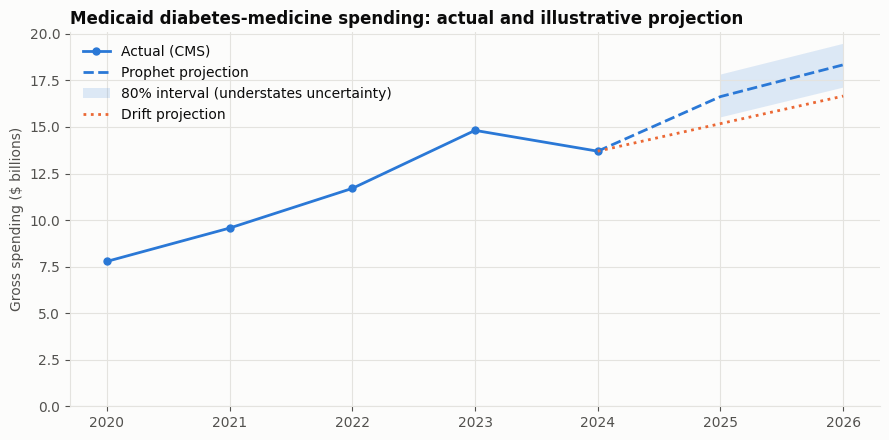

In [14]:
y = series["All diabetes"].values / 1e9
yhat, band = forecast_prophet(series["All diabetes"].values.astype(float), 2020, 2, return_interval=True)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(years, y, color=BLUE, marker="o", markersize=5, label="Actual (CMS)")
proj_years = [2024, 2025, 2026]
ax.plot(proj_years, np.r_[y[-1], yhat / 1e9], color=BLUE, linestyle="--", label="Prophet projection")
ax.fill_between([2025, 2026], band[:, 0] / 1e9, band[:, 1] / 1e9, color=BLUE, alpha=0.15, linewidth=0, label="80% interval (understates uncertainty)")
ax.plot(proj_years, np.r_[y[-1], forecast_drift(y, 2)], color=ORANGE, linestyle=":", label="Drift projection")
ax.set_xticks(years + [2025, 2026])
ax.set_ylim(bottom=0)
ax.set_ylabel("Gross spending ($ billions)")
ax.set_title("Medicaid diabetes-medicine spending: actual and illustrative projection")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(FIGS / "projection_all_diabetes.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Findings

All figures are gross, pre-rebate Medicaid spending from the CMS DY2024 file. Obesity-labeled incretins are excluded.

1. **Diabetes-medicine spending rose from \$7.78bn (2020) to \$13.70bn (2024)**, a 15.2% compound annual growth rate. It peaked at \$14.82bn in 2023, and 2024 was the first decline.
2. **Incretins now dominate.** GLP-1 / GIP-GLP-1 receptor agonists grew from \$1.50bn to \$7.21bn (CAGR 48.1%), rising from 19.3% to 52.6% of diabetes spending. Ozempic alone accounted for \$3.41bn in 2024. SGLT2 inhibitors grew from \$0.81bn to \$3.34bn (CAGR 42.6%).
3. **For these two classes the growth was mostly volume.** Of the GLP-1 class's 157 log points of growth, about 139 came from more claims. Across all diabetes medicines, most growth (44 of 57 log points) came from higher spending per claim. That aggregate figure mostly reflects a **mix shift** toward costlier branded incretins, not price rises on the same drugs.
4. **Insulin gross spending fell 57% from 2023 to 2024 while claims fell 10.5%.** Seven of the eight largest insulin products fell 69–79% in spending (Basaglar, −31%, is the exception); Lantus Solostar fell 73% in spending while its claims rose 14.5%. That is consistent with the 2024 list-price changes. Net (post-rebate) cost changes can't be measured from this file.
5. **Obesity-labeled incretins** (Wegovy, Zepbound, Saxenda) grew from \$0.01bn to \$1.56bn. Counting them as diabetes drugs would overstate diabetes spending by about 11% in 2024.

**Forecasting result (negative):** in the 2020–2022 → 2023–2024 backtest, **simple drift had the lowest average error (MAPE 24.3%)**. Linear trend (25.5%) and Prophet (25.6%) were essentially identical; with no changepoints on three annual points, Prophet reduces to a linear trend. Naive did worst (34.9%). No model anticipated the 2024 insulin drop (MAPE ≈74–76% for insulin). With annual data, Prophet adds nothing over a straight line. The 2025–2026 figures are illustrative scenarios, not forecasts.

## 10. Limitations

* **Gross spending before rebates.** Medicaid's statutory and supplemental rebates are large for brand-name drugs, so net cost is substantially lower and trends may differ.
* **No indication data.** SGLT2 inhibitors (heart failure, CKD) and some GLP-1 use may not be for diabetes. Obesity-labeled brands are excluded by brand name only.
* **Five annual points.** That's too few to validate any forecasting model; the backtest has only two held-out years per series.
* **National aggregates only.** No state, enrollee, or outcome detail. This file can't link spending to clinical outcomes such as HbA1c.
* **Data revisions.** CMS republishes this file each year and earlier years can be revised. The SHA-256 checksum pins the exact release used.